# COU 07506 – DIGITAL SIGNAL PROCESSING

## WEEK 1: LAB 0 – SETTING UP THE DSP LABORATORY

**Student Name:** EMMANUEL JOEL NZAVILO

**Registration Number:**250242455079

**Academic Year:** 2026/2027

**Semester:** I

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

In [2]:
n = np.arange(-5, 11)

print(n)

[-5 -4 -3 -2 -1  0  1  2  3  4  5  6  7  8  9 10]


In [3]:
delta = (n == 0).astype(float)

print(delta)

[0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [4]:
step = (n >= 0).astype(float)

print(step)

[0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [5]:
ramp = n * step

print(ramp)

[-0. -0. -0. -0. -0.  0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]


In [6]:
expo = 0.8**n * step

print(expo)

[0.         0.         0.         0.         0.         1.
 0.8        0.64       0.512      0.4096     0.32768    0.262144
 0.2097152  0.16777216 0.13421773 0.10737418]


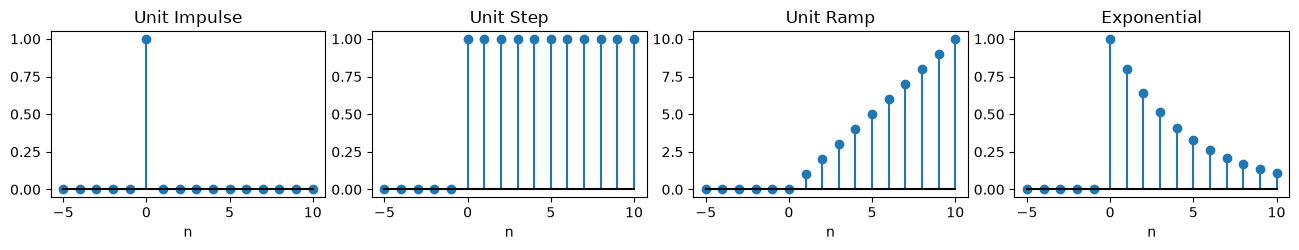

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["Unit Impulse", "Unit Step", "Unit Ramp", "Exponential"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

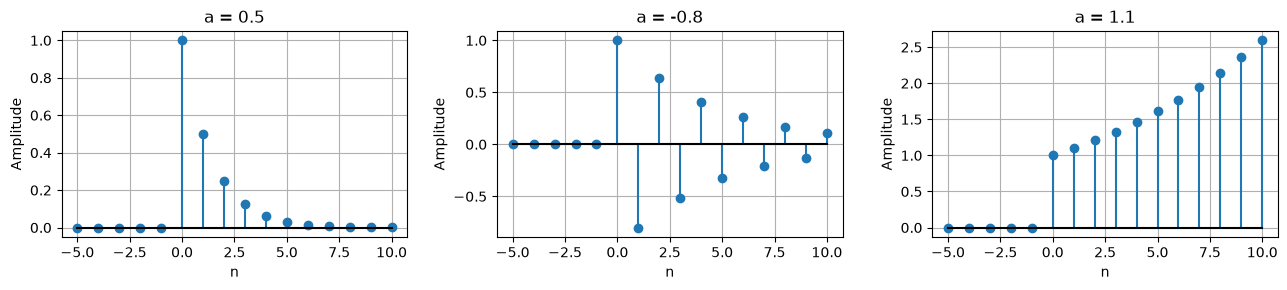

In [8]:
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))

for ax, a in zip(axes, a_values):
    x = a**n * step

    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

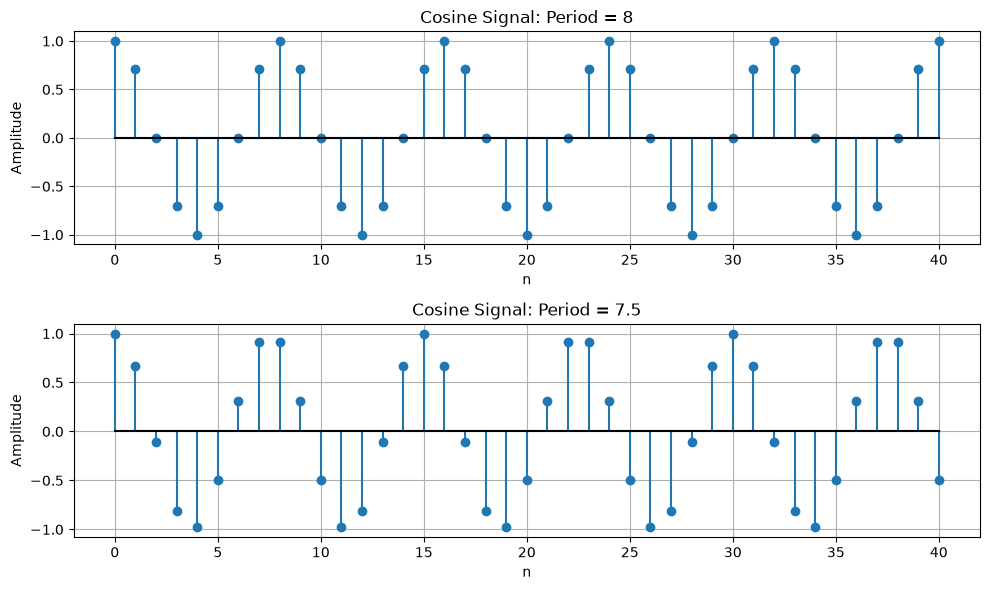

In [9]:
n2 = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n2 / 8)
x2 = np.cos(2 * np.pi * n2 / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n2, x1, basefmt="k-")
axes[0].set_title("Cosine Signal: Period = 8")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].stem(n2, x2, basefmt="k-")
axes[1].set_title("Cosine Signal: Period = 7.5")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [10]:
fs, audio = wavfile.read("myvoice.wav")

print("Sampling Frequency:", fs)
print("Audio Shape:", audio.shape)
print("Data Type:", audio.dtype)

Sampling Frequency: 44100
Audio Shape: (225792,)
Data Type: int16


In [11]:
duration = len(audio) / fs

print("Number of Samples:", len(audio))
print("Sampling Frequency:", fs, "Hz")
print("Duration:", duration, "seconds")

Number of Samples: 225792
Sampling Frequency: 44100 Hz
Duration: 5.12 seconds


In [12]:
audio_float = audio.astype(np.float32) / 32768.0

print("Original Data Type:", audio.dtype)
print("New Data Type:", audio_float.dtype)

print("Minimum Amplitude:", np.min(audio_float))
print("Maximum Amplitude:", np.max(audio_float))

Original Data Type: int16
New Data Type: float32
Minimum Amplitude: -0.61050415
Maximum Amplitude: 0.9999695


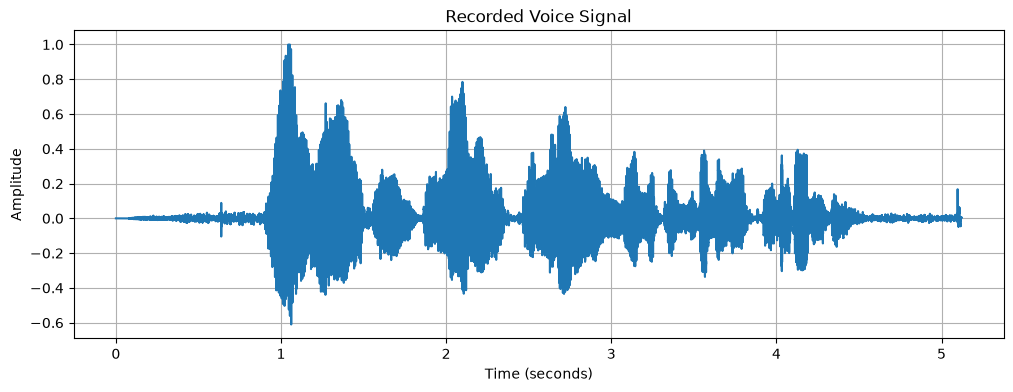

In [13]:
time = np.arange(len(audio_float)) / fs

plt.figure(figsize=(12, 4))

plt.plot(time, audio_float)

plt.title("Recorded Voice Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()

In [14]:
from IPython.display import Audio, display

display(Audio(audio_float, rate=fs))